# Where the contenders sit in shot-location space

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '07_contender_style_R'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
d = pd.read_csv(p / 'style_scores.csv')
assert len(d) == 30 and d.tricode.nunique() == 30
sas_cluster = d.loc[d.tricode.eq('SAS'), 'cluster'].iloc[0]
display(d.loc[d.cluster.eq(sas_cluster), ['tricode', 'PC1', 'PC2', 'net_rating']])
neighbors = pd.read_csv(p / 'spurs_style_neighbours.csv')
assert neighbors.distance.ge(0).all()
assert neighbors.distance.is_monotonic_increasing
display(neighbors.head(10))

,tricode,PC1,PC2,net_rating
0,ATL,-0.393557,0.649367,2.337524
2,CLE,0.400458,1.093128,4.042464
6,DEN,0.200900,-0.707342,4.879808
9,LAC,0.419328,-0.612980,1.154491
10,LAL,0.217362,-1.090659,1.756205
11,MIA,-1.312548,0.488040,2.221189
13,MIN,-0.379268,0.483764,3.450320
15,NYK,0.131828,-0.078576,6.414931
16,ORL,-1.606009,0.059893,0.621675
17,IND,0.723235,-0.329917,-7.763423


,tricode,distance,net_rating
0,ORL,1.372167,0.621675
1,NYK,1.722916,6.414931
2,ATL,2.052090,2.337524
3,MIN,2.205357,3.450320
4,UTA,2.339200,-8.038155
5,LAC,2.351849,1.154491
6,BKN,2.376721,-10.122984
7,DET,2.387471,8.058299
8,DEN,2.447867,4.879808
9,TOR,2.621113,2.822728


## Inspect the estimates

In [3]:
display(pd.read_csv(p / 'pca_loadings.csv'))

,feature,PC1,PC2
0,Pace,-0.334,0.151
1,Rim rate,-0.496,0.282
2,Short mid-range,-0.027,-0.616
3,Long mid-range,0.128,-0.570
4,Three-point rate,0.430,0.430
5,Corner-three share,-0.338,-0.052
6,Average shot distance,0.572,0.078


## Figures

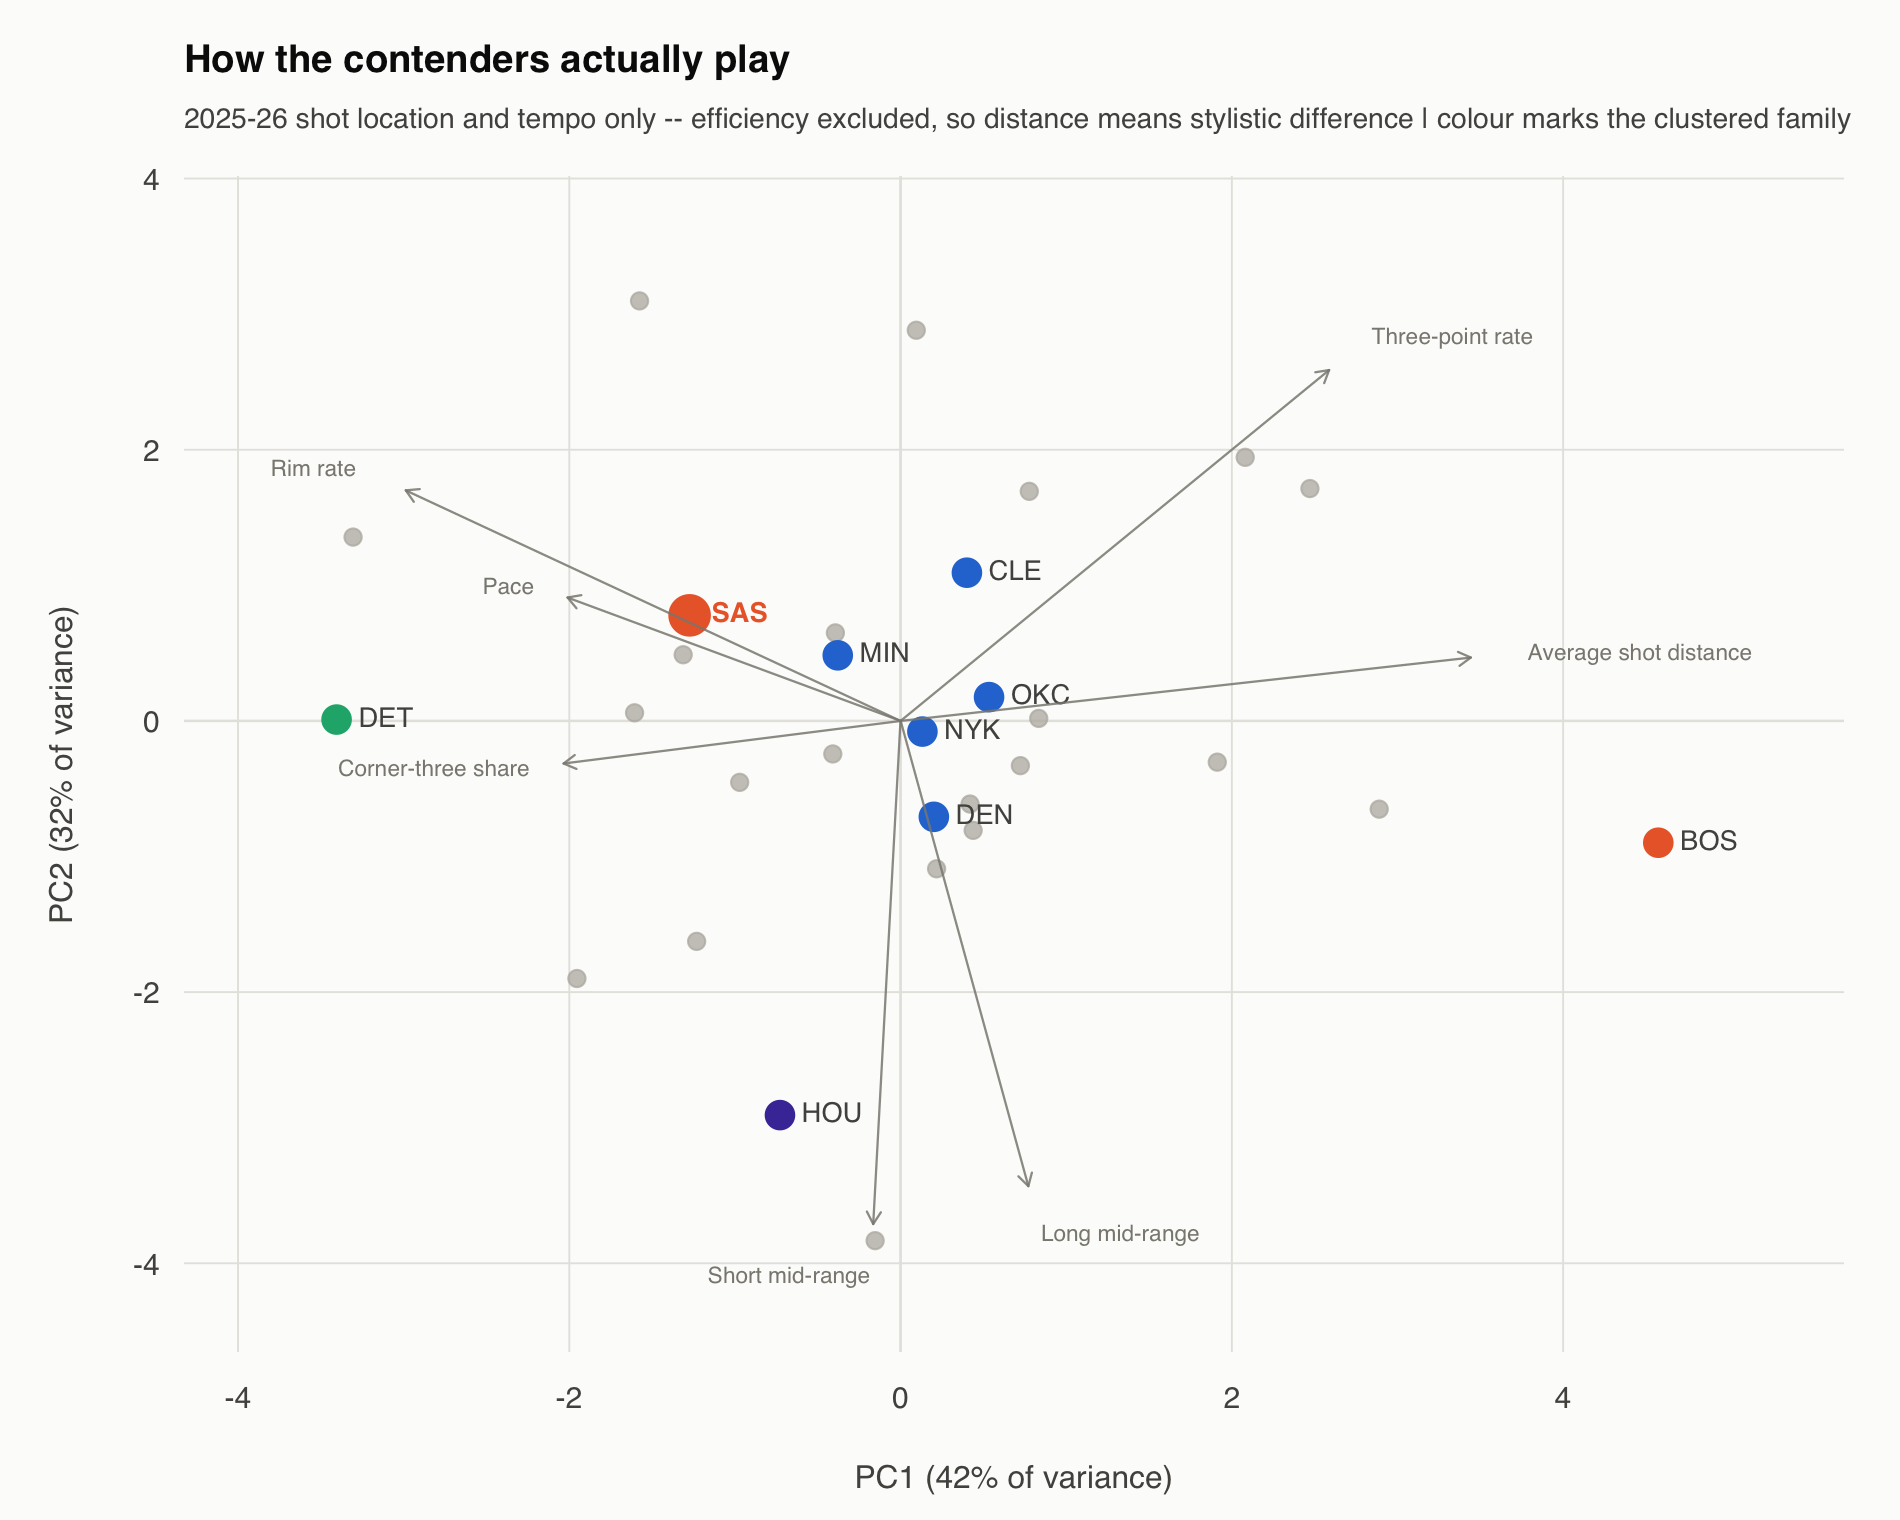

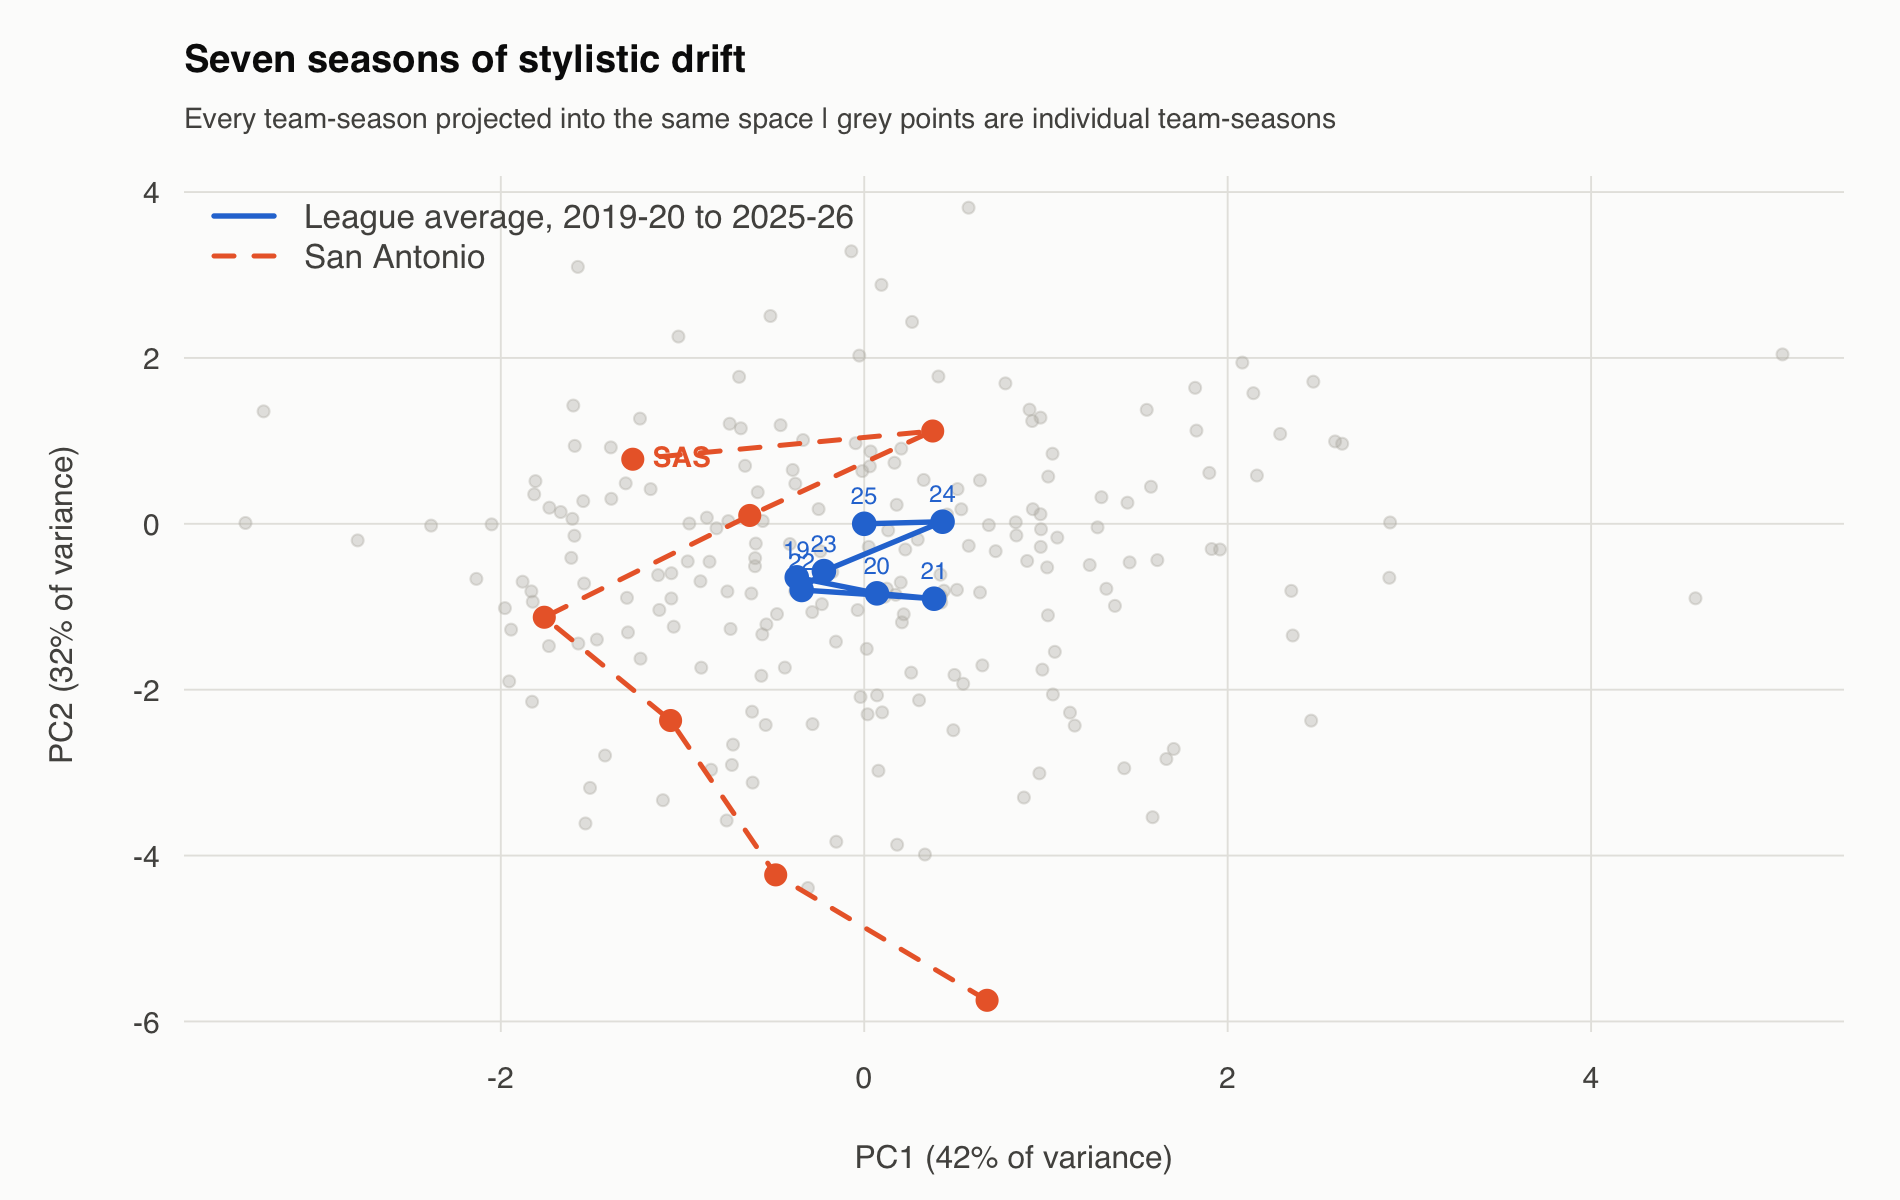

In [4]:
display(Image(filename=str(root / 'projects/07_contender_style_R/figures/style_space.png')))
display(Image(filename=str(root / 'projects/07_contender_style_R/figures/league_drift.png')))

## Interpretation limits
Distances describe the selected standardized shot-location features. Four clusters are a modeling choice, not an inferred number of NBA systems. The historical projection uses the current-season basis and is descriptive.